In [1]:
import numpy as np
import matplotlib.pyplot as plt

start_time = 0
seg_length = 10
sample_rate = 4096
t_range = np.arange(start_time, start_time+seg_length, 1/sample_rate)

In [2]:
def morlet_gabor_wavelet(A, phi, f, t0, Q):
    omega = 2 * np.pi * f
    tau = Q/omega

    dt = t_range - t0

    morlet_gabor_array = A*np.exp(-dt**2/tau**2)*np.cos(omega*dt+phi)

    return morlet_gabor_array

In [3]:
def compare_covariance(parameters_list_1, parameters_list_2):
    parameters_list_1 = np.array(parameters_list_1).T
    parameters_list_2 = np.array(parameters_list_2).T

    nm1 = np.shape(parameters_list_1)[1] - 1

    parameters_list_1_centered = parameters_list_1-np.mean(parameters_list_1, axis=1).reshape(-1,1)
    parameters_list_2_centered = parameters_list_2-np.mean(parameters_list_2, axis=1).reshape(-1,1)

    standard_covariance = np.einsum("pd,qd->pq", parameters_list_1_centered, parameters_list_2_centered)/nm1

    std1 = np.std(parameters_list_1_centered, ddof=1, axis=1)
    std2 = np.std(parameters_list_2_centered, ddof=1, axis=1)

    max_covariance = np.einsum("p,q->pq", std1, std2)
    max_error = np.trace(max_covariance.conj().T @ standard_covariance)

    zero_mean_covariance = np.einsum("pd,qd->pq", parameters_list_1, parameters_list_2)
    zero_mean_error = np.trace(zero_mean_covariance.conj().T @ standard_covariance)

    crossterm0mean = np.sqrt(np.sum(parameters_list_1**2))*np.sqrt(np.sum(parameters_list_2**2))/nm1

    data = [
        standard_covariance,
        max_covariance,
        max_error,
        zero_mean_covariance,
        zero_mean_error,
        crossterm0mean
    ]

    return data

# assume past wavelet was centered at f = 100, Q = 5
def dynamic_wavelets():
    A = np.exp(np.random.uniform(-25*np.log(2),-18*np.log(2))) #check
    phi = np.exp(np.random.uniform(0, np.log(2*np.pi))) #check
    t0 = np.random.choice([2.0, 2.0 + (1/4096)])
    funif = (np.random.uniform(0,sample_rate*2))
    fnorm = (np.random.normal(100,.0001)) 
    Qunif = (np.random.uniform(0.1,40))
    Qnorm = (np.random.normal(5, .0001)) 
    Q = 0.80*Qnorm + 0.20*Qunif
    f = 0.80*fnorm + 0.20*funif
    
    rand_wavelet = morlet_gabor_wavelet(A,phi,f,t0,Q)
    parameters = np.array([A,phi,t0,f,Q])
    return rand_wavelet, parameters

In [4]:
standard_covariance_list = []

max_covariance_list = []
max_error_list = []

zero_mean_covariance_list = []
zero_mean_error_list = []

for i in np.arange(1E3):
    parameters_list_1 = []
    parameters_list_2 = []

    for j in np.arange(2**4):
        wavelet_1j, parameters_1j = dynamic_wavelets()
        wavelet_2j, parameters_2j = dynamic_wavelets()

        parameters_list_1.append(parameters_1j)
        parameters_list_2.append(parameters_2j)

    standard_covariance, max_covariance, max_error, zero_mean_covariance, zero_mean_error, crossterm0mean = compare_covariance(parameters_list_1, parameters_list_2)

    standard_covariance_list.append(standard_covariance)

    max_covariance_list.append(max_covariance)
    max_error_list.append(max_error)

    zero_mean_covariance_list.append(zero_mean_covariance)
    zero_mean_error_list.append(zero_mean_error)

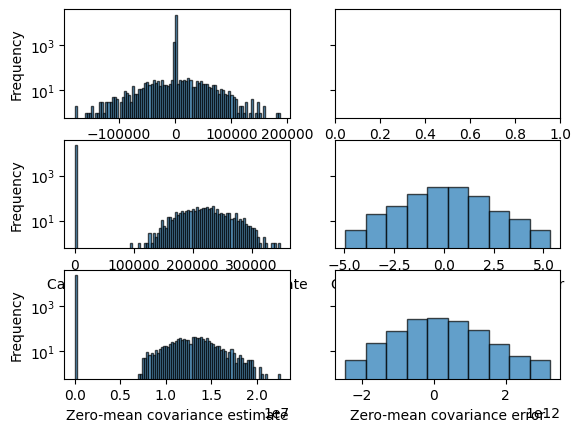

In [5]:
# PLOTTING

fig, ax = plt.subplots(nrows=3, ncols=2, sharey=True)

standard_covariance_list = np.array(standard_covariance_list)
max_covariance_list = np.array(max_covariance_list)
zero_mean_covariance_list = np.array(zero_mean_covariance_list)

max_error_list = np.array(max_error_list)
zero_mean_error_list = np.array(zero_mean_error_list)

# RASMIT - why would you remove 0???
# Remove zero, NaN, and infinity
standard_covariance_list = standard_covariance_list[np.isfinite(standard_covariance_list)]
max_covariance_list = max_covariance_list[np.isfinite(max_covariance_list)]
zero_mean_covariance_list = zero_mean_covariance_list[np.isfinite(zero_mean_covariance_list)]

max_error_list = max_error_list[np.isfinite(max_error_list)]
zero_mean_error_list = zero_mean_error_list[np.isfinite(zero_mean_error_list)]

ax[0][0].hist(
    standard_covariance_list,
    bins=100,
    edgecolor="black",
    alpha=0.7
)
# ax[0].xscale("log")

ax[1][0].hist(
    max_covariance_list,
    bins=100,
    edgecolor="black",
    alpha=0.7
)
ax[1][1].hist(
    max_error_list,
    bins=10,
    edgecolor="black",
    alpha=0.7
)
# ax[1].xscale("log")

ax[2][0].hist(
    zero_mean_covariance_list,
    bins=100,
    edgecolor="black",
    alpha=0.7
)
ax[2][1].hist(
    zero_mean_error_list,
    bins=10,
    edgecolor="black",
    alpha=0.7
)
# ax[2].xscale("log")

ax[0][0].set_xlabel("Standard covariance")
ax[1][0].set_xlabel("Cauchy-Schwarz covariance estimate")
ax[1][1].set_xlabel("Cauchy-Schwarz covariance error")
ax[2][0].set_xlabel("Zero-mean covariance estimate")
ax[2][1].set_xlabel("Zero-mean covariance error")

for i in [0, 1, 2]:
    ax[i][0].set_ylabel("Frequency")
    ax[i][0].set_yscale("log")
    ax[i][1].set_yscale("log")

plt.show()